# 01 · Czyszczenie danych z Reddita

**Cel:** zamienić surowe pliki `.jsonl` z Arctic Shift w tabelę, w której każdy komentarz ma flagi mówiące, dlaczego (jeśli w ogóle) nie nadaje się do analizy, i ocenić, ile użytecznych komentarzy zostaje na tydzień. Robimy to **przed** losowaniem próby, bo jeśli komentarzy jest za mało, trzeba zmienić parametry próby (np. próg długości albo liczbę komentarzy na tydzień).

**Zasady tego etapu**
- **Nic nie jest usuwane.** Każdy rekord dostaje flagi `f_*`, a `keep = True` tylko wtedy, gdy żadna flaga nie jest ustawiona. Dzięki temu można zrobić pełne EDA, także usuniętych komentarzy.
- Bez losowania próby, bez klasyfikacji emocji, bez testów statystycznych.
- Progi (3 słowa do wykrywania języka, pewność 0,9, 5 słów do duplikatów) pochodzą z `CLAUDE.md` i nie są tu zmieniane.
- Surowe pliki w `data/` są tylko do odczytu, wyniki trafiają do `processed/`.

**Układ notebooka:** 1 konfiguracja · 2 schemat i wybór kolumn · 3 kryteria odrzucenia i funkcje · 4 czyszczenie jednego pliku krok po kroku · 5 ten sam kod dla pliku, z zapisem wyników · 6 kandydaci na boty · 7 wszystkie pliki · 8 decyzje do podjęcia.

Interpretacje pod wynikami dotyczą pliku demonstracyjnego `r_democrats_comments_2012.jsonl` (w `CLAUDE.md` jest dla niego kontrola: 15 002 rekordów → 13 863 po kryteriach). Inny plik da inne liczby.

## 1. Konfiguracja

In [ ]:
import html
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lingua import LanguageDetectorBuilder
from tqdm.auto import tqdm

KATALOG = Path.cwd().parent          # notebook leży w <repo>/notebooks
DANE = KATALOG / "data"
WYNIKI = KATALOG / "processed"
(WYNIKI / "bot_candidates_parts").mkdir(parents=True, exist_ok=True)

PLIK_DEMO = DANE / "r_democrats_comments_2020.jsonl"
ROK_DEMO = int(PLIK_DEMO.stem.split("_")[-1])     # rok z nazwy pliku = okno czasowe
URUCHOM_WSZYSTKIE = False            # True = sekcja 7 przetworzy wszystkie pliki z data/ (to potrwa godziny)

# Kryteria z CLAUDE.md - nie zmieniać bez pytania
BOT_ACCOUNTS = {"automoderator"}
MIN_SLOW_JEZYK = 3                   # język sprawdzamy dopiero od 3 słów
PROG_PEWNOSCI = 0.9                  # flagujemy "nie po angielsku" dopiero przy pewności >= 0,9
MIN_SLOW_DUPLIKAT = 5                # duplikaty sprawdzamy tylko dla tekstów od 5 słów
MIN_NA_TYDZIEN = 50                  # tydzień z mniejszą liczbą ważnych komentarzy jest pomijany
MAX_NA_TYDZIEN = 300                 # z tygodnia bierzemy wszystko, co jest, ale najwyżej tyle
ROZMIAR_PARTII = 200_000             # tyle wierszy naraz w pamięci przy wczytywaniu

# Kolory i styl wykresów: jeden odcień niebieskiego, szare osie i siatka
NIEBIESKI = "#2a78d6"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titlesize": 11,
})

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Okna czasowe i fazy cyklu** (z `CLAUDE.md`). Tydzień to poniedziałek–niedziela w UTC. Tydzień należy do fazy, w której wypada jego **czwartek**. Lata referencyjne (2014, 2018, 2022, tylko r/running i r/languagelearning) mają jedną fazę `rok_referencyjny`. Tygodnie, których czwartek nie wypada w żadnej fazie, dostają `phase = NaN` i zostają w danych.

In [2]:
OKNA = {                              # rok pliku: (pierwszy poniedziałek, ostatnia niedziela)
    2012: ("2011-03-21", "2013-03-17"),
    2014: ("2013-12-30", "2015-01-04"),
    2016: ("2015-03-16", "2017-03-19"),
    2018: ("2018-01-01", "2019-01-06"),
    2020: ("2019-03-18", "2021-03-21"),
    2022: ("2021-12-27", "2023-01-01"),
    2024: ("2023-03-20", "2025-03-16"),
}
LATA_REFERENCYJNE = [2014, 2018, 2022]

fazy = pd.DataFrame([
    (2012, "bazowa",        "2011-03-21", "2011-06-12"),
    (2012, "przedwyborcza", "2011-06-13", "2012-09-02"),
    (2012, "szczytowa",     "2012-09-03", "2012-11-05"),
    (2012, "przejsciowa",   "2012-11-06", "2013-01-19"),
    (2012, "powyborcza",    "2013-01-20", "2013-03-16"),
    (2016, "bazowa",        "2015-03-21", "2015-08-05"),
    (2016, "przedwyborcza", "2015-08-06", "2016-07-20"),
    (2016, "szczytowa",     "2016-07-21", "2016-11-07"),
    (2016, "przejsciowa",   "2016-11-08", "2017-01-19"),
    (2016, "powyborcza",    "2017-01-20", "2017-03-16"),
    (2020, "bazowa",        "2019-03-21", "2019-06-25"),
    (2020, "przedwyborcza", "2019-06-26", "2020-08-23"),
    (2020, "szczytowa",     "2020-08-24", "2020-11-02"),
    (2020, "przejsciowa",   "2020-11-03", "2021-01-19"),
    (2020, "powyborcza",    "2021-01-20", "2021-03-16"),
    (2024, "bazowa",        "2023-03-21", "2023-08-22"),
    (2024, "przedwyborcza", "2023-08-23", "2024-08-18"),
    (2024, "szczytowa",     "2024-08-19", "2024-11-04"),
    (2024, "przejsciowa",   "2024-11-05", "2025-01-19"),
    (2024, "powyborcza",    "2025-01-20", "2025-03-16"),
], columns=["cycle", "phase", "start", "end"])
fazy.to_csv(WYNIKI / "phases.csv", index=False)
fazy.groupby("cycle").size().to_frame("liczba_faz")

,liczba_faz
cycle,
2012,5
2016,5
2020,5
2024,5


## 2. Schemat pliku i wybór kolumn

Surowy komentarz z Arctic Shift ma od kilkunastu do kilkudziesięciu pól, a ich zestaw zmienia się między latami (inne w 2012, inne w 2020 i 2024). Poniżej sprawdzamy, które pola są w pliku demo i jak często. Oglądamy tylko **nazwy pól i liczby**, nie treść komentarzy ani nazwy autorów.

In [3]:
liczniki = {}
n = 0
with open(PLIK_DEMO, encoding="utf-8") as f:
    for linia in f:
        rekord = json.loads(linia)
        n += 1
        for pole in rekord:
            liczniki[pole] = liczniki.get(pole, 0) + 1

pola = pd.Series(liczniki).sort_values(ascending=False).to_frame("rekordow")
pola["udzial"] = (pola["rekordow"] / n).round(3)
print(f"Rekordów w pliku: {n:,}, pól: {len(pola)}")
pola

Rekordów w pliku: 15,002, pól: 23


,rekordow,udzial
archived,15002,1.000
author,15002,1.000
author_flair_css_class,15002,1.000
author_flair_text,15002,1.000
body,15002,1.000
controversiality,15002,1.000
created_utc,15002,1.000
distinguished,15002,1.000
downs,15002,1.000
edited,15002,1.000


**Schemat pliku — co jest w danych**

Co widać:
- 22 z 23 pól jest wypełnionych w 100% rekordów; `removal_reason` tylko w 11,2% (1 686) — to pole z dawnych wersji API, nie używamy go.
- Pola `ups`, `downs`, `gilded`, `controversiality`, `archived`, `score_hidden`, `name`, `subreddit_id`, `author_flair_*`, `distinguished`, `edited`, `permalink` nie odpowiadają na żadne pytanie badawcze, więc ich nie wczytujemy.
- `author` i `body` są potrzebne tylko w trakcie czyszczenia; **w pliku wynikowym ich nie ma** (tekst zostaje jako oczyszczone `text`, autor tylko jako flaga `author_deleted`).

Zostawiamy minimum potrzebne do flag, tygodni i późniejszego losowania, plus trzy pola pomocnicze (`score`, `is_top_level`, `author_deleted`), które nic nie kosztują, a mogą się przydać w EDA (np. czy usunięte konta częściej piszą w szczycie kampanii).

**Które kolumny zostają w wynikach i dlaczego**

| Kolumna | Skąd | Po co |
|---|---|---|
| `id`, `link_id`, `parent_id` | surowe pola | łączą komentarz z wątkiem i rodzicem; `id` pozwala wrócić do surowego rekordu |
| `subreddit`, `type` | surowe pole, stała `comment` | łączenie plików i (później) postów |
| `created_utc`, `week_start` | surowe pole, wyliczone | oś czasu; tydzień pon–niedz UTC jest jednostką analizy |
| `cycle`, `phase` | wyliczone z okna i faz | cykl wyborczy i faza (reguła czwartku) |
| `retrieved_on` | surowe pole | opóźnienie archiwizacji (`retrieved_on − created_utc`) pokazuje, czy braki danych różnią się między cyklami; w części rekordów 2024 pole nie występuje (wtedy `NaN`) |
| `text`, `n_words` | wyczyszczona treść | wejście dla modelu emocji; `n_words` do wyboru progu długości |
| `lang`, `lang_conf` | detektor `lingua` | do analizy wrażliwości progu języka |
| `f_deleted` … `f_duplicate`, `keep` | flagi | powody odrzucenia; `keep` = żadna flaga |
| `author_deleted` | `author == "[deleted]"` | konto autora usunięte, to inne zjawisko niż usunięta treść (często treść zostaje) |
| `score`, `is_top_level` | surowe pole, `parent_id` zaczyna się od `t3_` | **dodatkowe, do Twojej decyzji:** ocena komentarza i informacja, czy to odpowiedź na post, czy na inny komentarz. Kosztują prawie nic, a bez nich trzeba by powtarzać wielogodzinne liczenie języka |

**Odpadają:** `author` (potrzebny tylko do flagi bota i liczby autorów, po tym jest usuwany), `body` (zastąpione przez `text`), oraz kilkadziesiąt pól technicznych Reddita (flair, nagrody, `gildings`, `stickied`, `collapsed`, `edited` itd.), które nie dotyczą pytania badawczego i pojawiają się tylko w niektórych latach, więc nie dałoby się ich porównać między cyklami.

In [4]:
# Pola, które w ogóle wczytujemy z pliku (reszta jest pomijana już przy wczytywaniu)
KOLUMNY_WEJSCIOWE = ["id", "author", "body", "created_utc", "retrieved_on",
                     "link_id", "parent_id", "score", "distinguished", "subreddit"]

## 3. Kryteria odrzucenia i funkcje czyszczące

Każde kryterium to osobna kolumna logiczna. Kolejność liczenia lejka jest stała (od najtańszych do najdroższych obliczeniowo):

| # | Flaga | Co oznacza | Dlaczego odrzucamy |
|---|---|---|---|
| 1 | `f_deleted` | treść to `[deleted]` lub `[removed]` | brak tekstu do analizy |
| 2 | `f_moderator` | `distinguished == "moderator"` | komentarz urzędowy moderacji (regulamin, ogłoszenia), nie głos użytkownika |
| 3 | `f_bot` | autor na liście `BOT_ACCOUNTS` (na start tylko AutoModerator) | tekst generowany automatycznie |
| 4 | `f_no_text` | po czyszczeniu 0 słów | sam link, obraz albo cytat |
| 5 | `f_not_english` | `lingua`: najpewniejszy język ≠ angielski i pewność ≥ 0,9 (tylko od 3 słów, tekst zamieniony na małe litery) | model emocji jest angielski |
| 6 | `f_duplicate` | ten sam tekst (małe litery) w tym samym subreddicie i tygodniu, tylko od 5 słów; zostaje pierwsze wystąpienie | spam i kopiowane komunikaty zawyżałyby jedną emocję |

**Czego świadomie nie robimy:** nie stosujemy progu długości jako filtra (próg 3, 5 lub 10 słów wybierzemy przy losowaniu i sprawdzimy w analizie wrażliwości), nie wykluczamy komentarzy z `[deleted]` w polu autora, jeśli mają treść, i nie szukamy botów po samym fragmencie „bot” w nazwie (łapie ludzi, np. `robotevil`, `botulizard`), tylko zapisujemy kandydatów do ręcznego przejrzenia.

**Czyszczenie tekstu** (w tej kolejności): `html.unescape` → usunięcie linii zaczynających się od `>` (cytaty) → `[tekst](url)` na `tekst` → usunięcie URL-i → usunięcie znaków `*~^` `` ` `` `#` → zwinięcie białych znaków. Nie zamieniamy na małe litery, nie usuwamy stopwords i nie lematyzujemy, bo model transformerowy potrzebuje pełnego tekstu.

**Wczytywanie porcjami.** Z każdego rekordu bierzemy tylko pola z `KOLUMNY_WEJSCIOWE`. Plik czytamy samodzielnie przez `json.loads`, a nie `pd.read_json`, bo schemat zmienia się między latami, a większość pól jest zagnieżdżona i niepotrzebna. Identyfikatory zostają tekstem, tak jak wymaga tego `dtype=False`.

In [5]:
def czytaj_partiami(sciezka, rozmiar=ROZMIAR_PARTII, limit=None):
    """Czyta plik .jsonl porcjami po `rozmiar` wierszy i oddaje je jako DataFrame."""
    wiersze = []
    liczba = 0
    with open(sciezka, encoding="utf-8") as f:
        for linia in f:
            rekord = json.loads(linia)
            wiersz = {pole: rekord.get(pole) for pole in KOLUMNY_WEJSCIOWE}
            # pojedyncze, uszkodzone znaki (surogaty) w treści uniemożliwiają późniejszy zapis do parquet
            if wiersz["body"] is not None:
                wiersz["body"] = wiersz["body"].encode("utf-8", "ignore").decode("utf-8")
            wiersze.append(wiersz)
            liczba += 1
            if len(wiersze) == rozmiar:
                yield pd.DataFrame(wiersze)
                wiersze = []
            if limit is not None and liczba >= limit:
                break
    if wiersze:
        yield pd.DataFrame(wiersze)

**Czyszczenie tekstu i flagi proste** (nie potrzebują całego pliku, więc liczymy je porcjami).

In [6]:
def czysc_tekst(tekst):
    """Czyści serię tekstów w kolejności z CLAUDE.md. Wielkość liter zostaje."""
    t = tekst.fillna("").astype(str)
    t = t.map(html.unescape)                                            # 1. &gt; &amp; -> > &
    t = t.str.replace(r"(?m)^[ \t]*>.*$", "", regex=True)               # 2. cytaty: linie od znaku >
    t = t.str.replace(r"\[([^\]]*)\]\([^)]*\)", r"\1", regex=True)     # 3. [tekst](url) -> tekst
    t = t.str.replace(r"https?://\S+|www\.\S+", "", regex=True)         # 4. gołe adresy URL
    t = t.str.replace(r"[*~^`#]", "", regex=True)                       # 5. znaczniki markdown
    t = t.str.replace(r"\s+", " ", regex=True).str.strip()              # 6. białe znaki
    return t


def dodaj_flagi_proste(df):
    """Flagi 1-4 (usunięte, moderator, bot, brak tekstu) oraz text, n_words, author_deleted."""
    body = df["body"].fillna("").astype(str).str.strip()
    df["f_deleted"] = body.isin(["[deleted]", "[removed]"])
    df["f_moderator"] = df["distinguished"].eq("moderator")
    df["f_bot"] = df["author"].fillna("").str.lower().isin(BOT_ACCOUNTS)
    df["text"] = czysc_tekst(df["body"])
    df["n_words"] = df["text"].str.split().str.len()
    df["f_no_text"] = df["n_words"].eq(0)
    df["author_deleted"] = df["author"].eq("[deleted]")
    return df.drop(columns=["body"])        # body jest duży i od teraz niepotrzebny

**Test czyszczenia na ręcznie zrobionych przykładach.** Te same przykłady sprawdzają kolejność kroków i to, czy poszczególne reguły robią to, co mają.

In [7]:
przyklady = pd.Series([
    "Normal comment, nothing to clean.",
    "&gt; quoted line from someone else\nMy answer under the quote.",
    "Read [this article](https://example.com/a?b=1) before voting.",
    "https://example.com/only-a-link",
    "See www.example.org for **details** and ~~more~~ ^things",
    "> only a quote",
    "THIS IS SHOUTED   with    spaces\n\nand lines",
])
oczekiwane = [
    "Normal comment, nothing to clean.",
    "My answer under the quote.",
    "Read this article before voting.",
    "",
    "See for details and more things",
    "",
    "THIS IS SHOUTED with spaces and lines",
]
wynik = czysc_tekst(przyklady)
for wejscie, wyjscie, wzor in zip(przyklady, wynik, oczekiwane):
    assert wyjscie == wzor, (wejscie, wyjscie, wzor)

pd.DataFrame({"przed": przyklady.str.replace("\n", " ⏎ "), "po": wynik, "slow": wynik.str.split().str.len()})

,przed,po,slow
0,"Normal comment, nothing to clean.","Normal comment, nothing to clean.",5
1,&gt; quoted line from someone else ⏎ My answer...,My answer under the quote.,5
2,Read [this article](https://example.com/a?b=1)...,Read this article before voting.,5
3,https://example.com/only-a-link,,0
4,See www.example.org for **details** and ~~more...,See for details and more things,6
5,> only a quote,,0
6,THIS IS SHOUTED with spaces ⏎ ⏎ and lines,THIS IS SHOUTED with spaces and lines,7


**Test czyszczenia na ręcznych przykładach**

Wszystkie asserty przeszły, czyli każdy krok robi dokładnie to, co opisuje tabela kryteriów:
- cytat (`> ...`) znika w całości, odpowiedź pod nim zostaje,
- link w markdownie `[tekst](url)` daje sam `tekst`, goły URL znika,
- znaczniki `*`, `~`, `^`, `` ` ``, `#` znikają, a wielkość liter zostaje (WIELKIE LITERY mogą nieść emocję),
- komentarz złożony wyłącznie z linku lub cytatu daje pusty tekst i `n_words = 0` — trafi do flagi `f_no_text`.

Sens: o tym, co jest „treścią" komentarza, decydują wyłącznie reguły, które widzimy w kodzie. Bez lematyzacji i bez usuwania stopwords, bo modele emocji (transformery) potrzebują naturalnego zdania.

**Wykrywanie języka.** Najwolniejszy krok, dlatego liczymy go tylko dla komentarzy, które mają szansę zostać (nie mają flag 1–4) i mają co najmniej 3 słowa. Reszta dostaje `lang = NaN`. Tekst zamieniamy na **małe litery**: krótkie, PISANE WIELKIMI LITERAMI angielskie komentarze (często gniewne) były mylone z innymi językami, co systematycznie zaniżałoby emocje negatywne. Wywołanie `..._in_parallel` używa wszystkich rdzeni procesora.

In [8]:
detektor = LanguageDetectorBuilder.from_all_languages().build()


def wykryj_jezyk(df):
    """Zapisuje lang i lang_conf oraz flagę f_not_english (flaga 5)."""
    bez_flag = ~df[["f_deleted", "f_moderator", "f_bot", "f_no_text"]].any(axis=1)
    do_sprawdzenia = bez_flag & (df["n_words"] >= MIN_SLOW_JEZYK)
    teksty = df.loc[do_sprawdzenia, "text"].str.lower().tolist()
    wyniki = detektor.compute_language_confidence_values_in_parallel(teksty)
    df["lang"] = None
    df["lang_conf"] = np.nan
    df.loc[do_sprawdzenia, "lang"] = [w[0].language.iso_code_639_1.name.lower() for w in wyniki]
    df.loc[do_sprawdzenia, "lang_conf"] = [w[0].value for w in wyniki]
    # tekst bez liter (same cyfry, emoji) daje pewność 0 i przypadkowy język, więc go nie zapisujemy
    df.loc[df["lang_conf"] == 0, "lang"] = None
    df["f_not_english"] = do_sprawdzenia & df["lang"].notna() & df["lang"].ne("en") & (df["lang_conf"] >= PROG_PEWNOSCI)
    return df

**Tydzień, faza i duplikaty** wymagają całego pliku (duplikat może leżeć w innej porcji niż oryginał), więc liczymy je po złożeniu porcji. W duplikatach porównujemy **skrót** (hash) tekstu zamiast samego tekstu, żeby oszczędzić pamięć przy plikach z milionami komentarzy.

In [9]:
def dodaj_tydzien_i_faze(df, rok):
    """week_start (poniedziałek UTC), cycle i phase. Faza = ta, w której wypada czwartek tygodnia."""
    df["created_utc"] = pd.to_numeric(df["created_utc"], errors="coerce")
    dzien = pd.to_datetime(df["created_utc"], unit="s").dt.normalize()
    df["week_start"] = dzien - pd.to_timedelta(dzien.dt.weekday, unit="D")
    czwartek = df["week_start"] + pd.Timedelta(days=3)
    df["cycle"] = rok
    df["phase"] = None
    if rok in LATA_REFERENCYJNE:
        df.loc[czwartek.dt.year == rok, "phase"] = "rok_referencyjny"
    else:
        for _, faza in fazy[fazy["cycle"] == rok].iterrows():
            w_fazie = (czwartek >= pd.Timestamp(faza["start"])) & (czwartek <= pd.Timestamp(faza["end"]))
            df.loc[w_fazie, "phase"] = faza["phase"]
    return df


def dodaj_duplikaty(df):
    """Flaga 6: ten sam tekst w tym samym subreddicie i tygodniu; zostaje pierwszy według created_utc."""
    kolejnosc = df.sort_values("created_utc", kind="stable").index
    klucz = pd.DataFrame({
        "subreddit": df["subreddit"],
        "week_start": df["week_start"],
        "hash": pd.util.hash_pandas_object(df["text"].str.lower(), index=False),
    }).loc[kolejnosc]
    klucz = klucz[df.loc[kolejnosc, "n_words"] >= MIN_SLOW_DUPLIKAT]
    powtorki = klucz.duplicated(keep="first")          # pierwsze wystąpienie nie jest powtórką
    df["f_duplicate"] = False
    df.loc[powtorki[powtorki].index, "f_duplicate"] = True
    return df

**Lejek i tabela tygodniowa.** Flagi się nakładają (komentarz może być jednocześnie usunięty i bez tekstu), więc lejek pokazuje, ile **nowych** komentarzy odpada na każdym kroku w ustalonej kolejności.

In [10]:
KOLEJNOSC_FLAG = ["f_deleted", "f_moderator", "f_bot", "f_no_text", "f_not_english", "f_duplicate"]


def lejek(df):
    """Ile nowych komentarzy odpada na każdym kroku i ile zostaje."""
    zostaje = len(df)
    odpadle = pd.Series(False, index=df.index)
    wiersze = [{"krok": "surowe", "odpada": 0, "zostaje": zostaje, "flaga_lacznie": 0}]
    for flaga in KOLEJNOSC_FLAG:
        nowe = int((df[flaga] & ~odpadle).sum())
        odpadle |= df[flaga]
        zostaje -= nowe
        wiersze.append({"krok": flaga, "odpada": nowe, "zostaje": zostaje, "flaga_lacznie": int(df[flaga].sum())})
    return pd.DataFrame(wiersze)


def tygodniowe(df, rok):
    """Tabela na tydzień okna. Tygodnie bez żadnego komentarza też są (z zerem), żeby luki były widać."""
    start, koniec = OKNA[rok]
    tygodnie = pd.date_range(start, koniec, freq="7D")           # poniedziałki
    keep = df[df["keep"]]
    tab = pd.DataFrame(index=tygodnie)
    tab["n_raw"] = df.groupby("week_start").size()
    tab["share_deleted"] = df.groupby("week_start")["f_deleted"].mean()
    for prog in (3, 5, 10):
        tab[f"n_valid_{prog}w"] = keep[keep["n_words"] >= prog].groupby("week_start").size()
    tab["n_authors"] = keep[~keep["author_deleted"]].groupby("week_start")["author"].nunique()
    liczby = ["n_raw", "n_valid_3w", "n_valid_5w", "n_valid_10w", "n_authors"]
    tab[liczby] = tab[liczby].fillna(0).astype(int)
    # cykl i faza dla każdego tygodnia okna liczone tą samą funkcją co dla komentarzy
    tydzien = pd.DataFrame({"created_utc": (tygodnie - pd.Timestamp("1970-01-01")) // pd.Timedelta("1s")})
    tydzien = dodaj_tydzien_i_faze(tydzien, rok)
    tab["cycle"] = tydzien["cycle"].values
    tab["phase"] = tydzien["phase"].values
    tab.index.name = "week_start"
    return tab

## 4. Czyszczenie jednego pliku krok po kroku

Plik demo jest mały, więc wczytujemy go w całości i idziemy po kryteriach po kolei, żeby widać było efekt każdego kroku.

In [11]:
t0 = time.time()
df = pd.concat(czytaj_partiami(PLIK_DEMO), ignore_index=True)
print(f"Wczytano {len(df):,} rekordów w {time.time() - t0:.1f} s")

Wczytano 15,002 rekordów w 0.3 s


### 4.1 Flagi proste: usunięte, moderator, bot, brak tekstu

In [12]:
df = dodaj_flagi_proste(df)
flagi_proste = ["f_deleted", "f_moderator", "f_bot", "f_no_text", "author_deleted"]
tab_proste = df[flagi_proste].sum().to_frame("rekordow")
tab_proste["udzial"] = (tab_proste["rekordow"] / len(df)).round(3)
tab_proste

,rekordow,udzial
f_deleted,1009,0.067
f_moderator,20,0.001
f_bot,0,0.000
f_no_text,76,0.005
author_deleted,2527,0.168


**Proste flagi (bez detekcji języka)**

Dla pliku r/democrats 2012 (15 002 komentarzy):
- `f_deleted`: 1 009 (6,7%) — treść `[deleted]` lub `[removed]`,
- `f_moderator`: 20 (0,1%) — `distinguished = moderator`,
- `f_bot`: 0 — na liście znanych botów jest tylko AutoModerator, a w tym pliku nie ma jego komentarzy,
- `f_no_text`: 76 (0,5%) — po czyszczeniu nie zostaje ani jedno słowo.

Ciekawostka: `author_deleted` (konto usunięte, ale treść komentarza zostaje) dotyczy aż 2 527 rekordów (16,8%), czyli ponad dwa razy więcej niż usunięte treści. Takie komentarze **zostają** w próbie, ale liczba unikalnych autorów (`n_authors`) będzie zaniżona — trzeba o tym pamiętać, jeśli kiedyś chcemy liczyć komentarze na autora.

### 4.2 Język

In [13]:
t0 = time.time()
df = wykryj_jezyk(df)
czas_jezyka = time.time() - t0
sprawdzone = df["lang"].notna()
szybkosc_jezyka = sprawdzone.sum() / czas_jezyka
print(f"Sprawdzono język {sprawdzone.sum():,} komentarzy w {czas_jezyka:.0f} s ({szybkosc_jezyka:.0f} komentarzy/s)")

# Jak wynik zależy od progu pewności (używamy 0,9; pozostałe wartości tylko do porównania)
nie_angielski = df[sprawdzone & df["lang"].ne("en")]
progi = pd.DataFrame({"prog_pewnosci": [0.5, 0.7, 0.9, 0.99]})
progi["oflagowane"] = [int((nie_angielski["lang_conf"] >= p).sum()) for p in progi["prog_pewnosci"]]
progi

Sprawdzono język 13,384 komentarzy w 28 s (484 komentarzy/s)


,prog_pewnosci,oflagowane
0,0.50,8
1,0.70,2
2,0.90,1
3,0.99,0


**Detekcja języka (lingua)**

- Sprawdziliśmy 13 384 komentarze (tylko te bez wcześniejszej flagi i z co najmniej 3 słowami), tempo ok. 500 komentarzy/s przy kilku rdzeniach.
- Przy progu pewności 0,9 flagą `f_not_english` oznaczono tylko **1** komentarz; przy 0,5 byłoby to 8, przy 0,99 żaden.

Subreddity polityczne są po angielsku, więc ta flaga ma usuwać tylko wyraźne wyjątki. Niski próg (0,5) łapałby głównie krótkie angielskie komentarze z wulgaryzmami lub slangiem, które lingua myli z innymi językami — to byłaby strata dobrych danych. Próg 0,9 jest ostrożny; jeśli w innych plikach flag będzie dużo, warto zajrzeć w próbkę i ewentualnie go zmienić.

Uwaga praktyczna: to jest najwolniejszy krok całego czyszczenia (rząd godzin dla wszystkich plików), więc partie zapisują się osobno i można wznowić przerwane przetwarzanie.

### 4.3 Tydzień, faza, duplikaty i `keep`

In [14]:
df = dodaj_tydzien_i_faze(df, ROK_DEMO)
df = dodaj_duplikaty(df)
df["keep"] = ~df[KOLEJNOSC_FLAG].any(axis=1)
print(f"keep = True: {df['keep'].sum():,} z {len(df):,}")
df.groupby("phase", dropna=False).size().to_frame("komentarzy")

keep = True: 13,862 z 15,002


,komentarzy
phase,
bazowa,492
powyborcza,2412
przedwyborcza,7180
przejsciowa,2583
szczytowa,2335


**Tydzień i faza kampanii**

- Każdy komentarz dostaje `week_start` (poniedziałek, UTC) i fazę tygodnia według jego **czwartku** (reguła z CLAUDE.md), więc żaden tydzień nie jest rozdarty między dwie fazy.
- W pliku 2012 najwięcej komentarzy mamy w fazie przedwyborczej (7 180) i powyborczej (2 412), czyli tam, gdzie wokół wyborów jest największy ruch; faza bazowa ma tylko 492.

Dlaczego to ważne: główne pytanie pracy to cykliczność emocji, więc liczebność w **fazie** jest tak samo istotna jak liczebność w całym roku. Faza bazowa już teraz wygląda na najbardziej zagrożoną niedoborem danych.

### 4.4 Lejek

         krok  odpada  zostaje  flaga_lacznie
       surowe       0    15002              0
    f_deleted    1009    13993           1009
  f_moderator      20    13973             20
        f_bot       0    13973              0
    f_no_text      76    13897             76
f_not_english       1    13896              1
  f_duplicate      34    13862             38


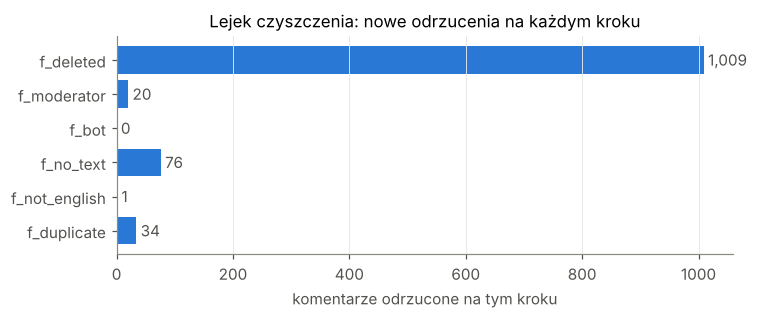

In [15]:
lej = lejek(df)
print(lej.to_string(index=False))

kroki = lej.iloc[1:]
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(kroki["krok"], kroki["odpada"], color=NIEBIESKI)
ax.invert_yaxis()
for i, v in enumerate(kroki["odpada"]):
    ax.text(v, i, f" {v:,}", va="center", color="#52514e")
ax.set_xlabel("komentarze odrzucone na tym kroku")
ax.set_title("Lejek czyszczenia: nowe odrzucenia na każdym kroku")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Lejek odrzuceń (jedna flaga = jeden krok)**

Z 15 002 komentarzy odpada:
- 1 009 usuniętych,
- 20 moderatorskich,
- 0 botów,
- 76 bez tekstu,
- 1 nieangielski,
- 34 duplikaty (łącznie flaga `f_duplicate` dotyczy 38 komentarzy, ale 4 miały już wcześniejszą flagę).

Zostaje **13 862** (92,4%). Prawie cała strata to komentarze usunięte; reszta jest marginalna. Kolejność kroków w lejku ma wpływ tylko na to, *któremu* krokowi przypisujemy komentarz z dwiema flagami — nie na końcową liczbę.

In [16]:
# Kontrola z CLAUDE.md dla tego pliku
KONTROLA_SUROWE, KONTROLA_PO_KRYTERIACH = 15_002, 13_863
print(f"surowe:        {len(df):>7,}  (oczekiwane {KONTROLA_SUROWE:,})")
print(f"po kryteriach: {df['keep'].sum():>7,}  (oczekiwane {KONTROLA_PO_KRYTERIACH:,})")
print(f"różnica: {df['keep'].sum() - KONTROLA_PO_KRYTERIACH:+d}")

surowe:         15,002  (oczekiwane 15,002)
po kryteriach:  13,862  (oczekiwane 13,863)
różnica: -1


**Kontrola z CLAUDE.md**

- Surowe: 15 002 — zgodne.
- Po kryteriach: 13 862 zamiast oczekiwanych 13 863, czyli różnica **jednego komentarza (0,007%)**.

Najbardziej prawdopodobna przyczyna to inna wersja lingua niż ta użyta przy pierwszym liczeniu: jeden graniczny komentarz po drodze zmienia klasyfikację z angielskiego na nie-angielski albo odwrotnie. Nie udowodniliśmy tego (nie mamy starego wyniku na poziomie pojedynczych rekordów), ale różnica jest o rzędy wielkości mniejsza od jakichkolwiek progów, które nas interesują, więc nie blokuje dalszej pracy. Dla powtarzalności zapiszemy wersję biblioteki w raporcie końcowym.

### 4.5 Długość tekstów

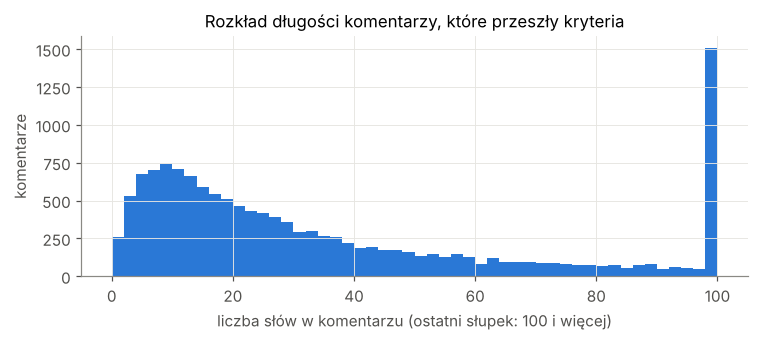

,udzial,mediana_slow
< 3 słów,0.037,24.0
< 5 słów,0.081,24.0
< 10 słów,0.210,24.0


In [17]:
slowa = df.loc[df["keep"], "n_words"]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(slowa.clip(upper=100), bins=range(0, 102, 2), color=NIEBIESKI)
ax.set_xlabel("liczba słów w komentarzu (ostatni słupek: 100 i więcej)")
ax.set_ylabel("komentarze")
ax.set_title("Rozkład długości komentarzy, które przeszły kryteria")
plt.tight_layout()
plt.show()

udzial_krotkich = pd.Series({f"< {p} słów": (slowa < p).mean() for p in (3, 5, 10)}).round(3).to_frame("udzial")
udzial_krotkich["mediana_slow"] = slowa.median()
udzial_krotkich

**Długość komentarzy (po czyszczeniu)**

- Mediana komentarza to 24 słowa.
- Poniżej 3 słów jest 3,7% użytecznych komentarzy, poniżej 5 słów — 8,1%, poniżej 10 słów — 21,0%.

Wybór progu długości kosztuje więc od kilku do dwudziestu kilku procent danych. Bardzo krótkie komentarze („lol", „this") ciężko jednoznacznie sklasyfikować emocjonalnie, dlatego nie filtrujemy na tym etapie, tylko zapisujemy `n_words` i decydujemy przy losowaniu. Rozkład ma długi prawy ogon, więc średnia byłaby myląca — raportujemy medianę.

### 4.6 Ile komentarzy zostaje na tydzień

In [ ]:
tab = tygodniowe(df, ROK_DEMO)

fig, ax = plt.subplots(figsize=(9, 3.6))
for prog, kolor in zip((3, 5, 10), ("#9ec5f4", NIEBIESKI, "#164a8a")):
    ax.plot(tab.index, tab[f"n_valid_{prog}w"], color=kolor, lw=1.6, label=f"od {prog} słów")
ax.axhline(MAX_NA_TYDZIEN, color="#8a8984", ls="--", lw=1)
ax.text(tab.index[0], MAX_NA_TYDZIEN, f" maksimum = {MAX_NA_TYDZIEN}", va="bottom", color="#52514e")
ax.axhline(MIN_NA_TYDZIEN, color="#8a8984", ls=":", lw=1)
ax.text(tab.index[0], MIN_NA_TYDZIEN, f" minimum = {MIN_NA_TYDZIEN}", va="bottom", color="#52514e")
ax.set_ylabel("komentarze na tydzień")
ax.set_title("Użyteczne komentarze na tydzień przy trzech progach długości")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

pod_celem = pd.DataFrame({"prog_slow": [3, 5, 10]})
pod_celem["tygodni_ponizej_50"] = [int((tab[f"n_valid_{p}w"] < MIN_NA_TYDZIEN).sum()) for p in pod_celem["prog_slow"]]
pod_celem["tygodni_ponizej_300"] = [int((tab[f"n_valid_{p}w"] < MAX_NA_TYDZIEN).sum()) for p in pod_celem["prog_slow"]]
pod_celem["z_tygodni"] = len(tab)
pod_celem

**Liczebność tygodniowa**

- Przy progu 3 słów **99** z 104 tygodni ma mniej niż 300 użytecznych komentarzy, przy 5 słowach — 100, przy 10 słowach — 101. To zgadza się z uwagą w CLAUDE.md (100/104).
- Linie dla trzech progów leżą bardzo blisko siebie, bo próg długości zmienia liczebność tylko o kilka–kilkanaście procent.
- Tylko okolice wyborów listopada 2012 (ok. 490 komentarzy w szczycie) i jeden skok na końcu okna (ok. 540) przekraczają 300.

Wniosek: **limit 300 komentarzy na tydzień jest dla r/democrats 2012 prawie nigdzie nie osiągany**, a ograniczeniem jest wielkość subreddita, nie próg długości. Zasada próby jest już przyjęta: z tygodnia bierzemy wszystko, co jest (od 50 do 300 ważnych komentarzy), a tygodnie poniżej 50 pomijamy. Skok na końcu okna (marzec 2013) warto sprawdzić osobno (wydarzenie czy anomalia, np. brygadowanie).

### 4.7 Udział usuniętych komentarzy w czasie

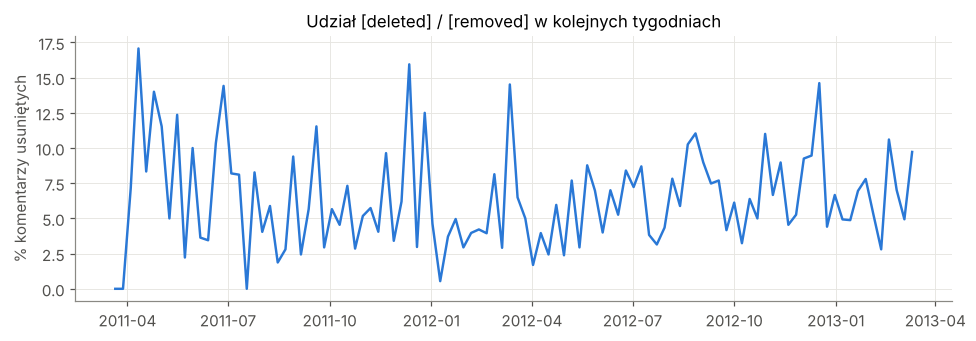

,share_deleted
count,104.000
mean,0.064
std,0.036
min,0.000
25%,0.040
50%,0.058
75%,0.084
max,0.171


In [19]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(tab.index, tab["share_deleted"] * 100, color=NIEBIESKI, lw=1.6)
ax.set_ylabel("% komentarzy usuniętych")
ax.set_title("Udział [deleted] / [removed] w kolejnych tygodniach")
plt.tight_layout()
plt.show()
tab["share_deleted"].describe().round(3).to_frame("share_deleted")

**Udział usuniętych komentarzy w czasie**

Średnio 6,4% tygodniowo (mediana 5,8%), ale rozrzut jest duży: od 0% do 17% — największe wartości pojawiają się głównie na początku okna, gdy komentarzy jest jeszcze mało, a przy małych liczbach jeden usunięty komentarz od razu mocno przesuwa udział. Nie widać wyraźnego trendu ani wyraźnego efektu wyborów.

Zostawiamy usunięte komentarze w pliku (flaga zamiast kasowania), bo udział usuniętych sam w sobie bywa wskaźnikiem toksyczności dyskusji (moderacja, wycofywanie się z rozmowy) i chcemy mieć go w pełnym EDA. Do losowania próby nie wchodzą, bo nie mają tekstu.

## 5. Ten sam kod dla całego pliku, z zapisem wyników

`przetworz_plik` wywołuje te same funkcje co sekcja 4, ale wczytuje plik porcjami i zapisuje wyniki do `processed/`:

- `{nazwa}_clean.parquet`: **wszystkie** rekordy z flagami (bez `author` i bez `body`),
- `{nazwa}_weekly.csv`: liczebności na tydzień,
- `{nazwa}_funnel.csv`: lejek,
- `bot_candidates_parts/{nazwa}.csv`: kandydaci na boty (jedyne miejsce, gdzie zapisujemy nazwy autorów).

Plik parquet zapisujemy **na końcu** (najpierw pod nazwą tymczasową), więc jego obecność znaczy, że plik jest przetworzony w całości. Dzięki temu przerwany przebieg można wznowić: gotowe pliki są pomijane.

In [20]:
KOLUMNY_WYJSCIOWE = (["id", "link_id", "parent_id", "subreddit", "type", "cycle", "phase", "week_start",
                      "created_utc", "retrieved_on", "text", "n_words", "lang", "lang_conf",
                      "author_deleted", "score", "is_top_level"] + KOLEJNOSC_FLAG + ["keep"])


def kandydaci_na_boty(df):
    """Autorzy z "bot" w nazwie (bez rozróżniania wielkości liter) i liczba ich wpisów, do ręcznego przejrzenia."""
    nazwy = df.loc[df["author"].fillna("").str.lower().str.contains("bot"), "author"]
    tab = nazwy.value_counts().rename_axis("author").reset_index(name="n")
    tab["nazwa_konczy_sie_na_bot"] = tab["author"].str.lower().str.contains(r"bot\d*$")   # tylko wskazówka
    return tab


def przetworz_plik(sciezka, limit=None):
    nazwa = sciezka.stem
    rok = int(nazwa.split("_")[-1])
    porcje = []
    for porcja in tqdm(czytaj_partiami(sciezka, limit=limit), desc=nazwa, unit="porcja"):
        porcja = dodaj_flagi_proste(porcja)
        porcje.append(wykryj_jezyk(porcja))
    df = pd.concat(porcje, ignore_index=True)
    df = dodaj_tydzien_i_faze(df, rok)
    df = dodaj_duplikaty(df)
    df["keep"] = ~df[KOLEJNOSC_FLAG].any(axis=1)

    poza_oknem = int((~df["week_start"].isin(pd.date_range(*OKNA[rok], freq="7D"))).sum())
    if poza_oknem:
        print(f"UWAGA {nazwa}: {poza_oknem:,} komentarzy leży poza oknem czasowym {OKNA[rok]}")

    tygodnie = tygodniowe(df, rok)               # korzysta z author, dlatego przed jego usunięciem
    boty = kandydaci_na_boty(df)
    lej = lejek(df)

    df["type"] = "comment"
    df["is_top_level"] = df["parent_id"].fillna("").str.startswith("t3_")
    df = df[KOLUMNY_WYJSCIOWE]                   # tu znika author

    tygodnie.to_csv(WYNIKI / f"{nazwa}_weekly.csv")
    lej.to_csv(WYNIKI / f"{nazwa}_funnel.csv", index=False)
    boty.to_csv(WYNIKI / "bot_candidates_parts" / f"{nazwa}.csv", index=False)
    tymczasowy = WYNIKI / f"{nazwa}_clean.parquet.tmp"
    df.to_parquet(tymczasowy, index=False)
    tymczasowy.replace(WYNIKI / f"{nazwa}_clean.parquet")      # parquet na końcu = znacznik "gotowe"
    return df, tygodnie, lej

In [21]:
t0 = time.time()
df_pliku, tab_pliku, lej_pliku = przetworz_plik(PLIK_DEMO)
czas_pliku = time.time() - t0
rozmiar_mb = PLIK_DEMO.stat().st_size / 1e6
print(f"{PLIK_DEMO.name}: {len(df_pliku):,} rekordów w {czas_pliku:.0f} s ({rozmiar_mb / czas_pliku:.2f} MB surowych danych na sekundę)")

# Ten sam kod, więc wynik musi być identyczny jak w sekcji 4
assert df_pliku["keep"].sum() == df["keep"].sum()
assert lej_pliku.equals(lej)
assert tab_pliku.equals(tab)
assert "author" not in df_pliku.columns and "body" not in df_pliku.columns
print("zgodność z sekcją 4: OK, kolumny author i body nie trafiły do wyniku")


r_democrats_comments_2012: 0porcja [00:00, ?porcja/s]


r_democrats_comments_2012: 1porcja [00:27, 27.93s/porcja]


r_democrats_comments_2012: 1porcja [00:27, 27.94s/porcja]

r_democrats_comments_2012.jsonl: 15,002 rekordów w 28 s (0.39 MB surowych danych na sekundę)
zgodność z sekcją 4: OK, kolumny author i body nie trafiły do wyniku


In [22]:
wynik = pd.read_parquet(WYNIKI / f"{PLIK_DEMO.stem}_clean.parquet")
print(f"parquet: {wynik.shape[0]:,} wierszy, {wynik.shape[1]} kolumn, "
      f"{(WYNIKI / f'{PLIK_DEMO.stem}_clean.parquet').stat().st_size / 1e6:.1f} MB na dysku")
wynik.drop(columns="text").dtypes.to_frame("typ").T

parquet: 15,002 wierszy, 24 kolumn, 2.9 MB na dysku


,id,link_id,parent_id,subreddit,type,cycle,phase,week_start,created_utc,retrieved_on,...,author_deleted,score,is_top_level,f_deleted,f_moderator,f_bot,f_no_text,f_not_english,f_duplicate,keep
typ,str,str,str,str,str,int64,str,datetime64[ms],int64,int64,...,bool,int64,bool,bool,bool,bool,bool,bool,bool,bool


**Zapis wyniku**

- Plik `_clean.parquet` ma 15 002 wiersze (wszystkie, także z flagami) i 24 kolumny, na dysku zajmuje ok. 2,9 MB (surowy `.jsonl` ma ok. 11 MB).
- Sprawdzenie zgodności z sekcją 4 przeszło: tabele i liczebności są identyczne, a kolumn `author` i `body` w wyniku nie ma.
- Parquet zapisywany jest jako ostatni (przez plik `.tmp`), więc jego istnienie oznacza, że plik został przetworzony w całości — dzięki temu można bezpiecznie wznawiać.

Wszystkie wiersze zostają, a `keep` wskazuje, które nadają się do analizy; usunięcie czegokolwiek z pliku odbyłoby się dopiero przy losowaniu próby.

## 6. Kandydaci na boty

In [23]:
boty = pd.read_csv(WYNIKI / "bot_candidates_parts" / f"{PLIK_DEMO.stem}.csv")
print(f"kandydatów: {len(boty)}, z nazwą kończącą się na 'bot': {boty['nazwa_konczy_sie_na_bot'].sum()}, "
      f"wpisów łącznie: {boty['n'].sum()}")

kandydatów: 9, z nazwą kończącą się na 'bot': 3, wpisów łącznie: 33


**Kandydaci na boty (do ręcznego przeglądu)**

W tym pliku jest 9 autorów, których nazwa zawiera „bot", z czego 3 kończą się na „bot"; razem napisali 33 komentarze (0,2% pliku). Nie wypisujemy nazw w notebooku (repozytorium jest na GitHubie), ale pełna lista trafia do `bot_candidates.csv` i ocenisz ją ręcznie.

Zawartość nazwy to tylko heurystyka — „Abbott" lub „bottle" też zawierają „bot". Dlatego automatycznie flagujemy wyłącznie AutoModeratora, a resztę dopisujemy do listy po przeglądzie; przy 33 komentarzach strata w tym pliku i tak byłaby pomijalna, ale w r/Conservative 2020/2024 boty mogą pisać dużo więcej.

## 7. Wszystkie pliki

Przed uruchomieniem sprawdzamy, co jest do zrobienia i ile to może potrwać. Szacunek jest zgrubny: bierze szybkość z pliku demo (rok 2012, krótkie rekordy, mało usuniętych), a późniejsze lata mają dłuższe rekordy i więcej usuniętych komentarzy, które pomijają wolną detekcję języka.

In [24]:
pliki = sorted(DANE.glob("r_*_comments_*.jsonl"), key=lambda p: p.stat().st_size)    # małe pierwsze, błędy wyjdą szybko
spis = pd.DataFrame({
    "plik": [p.name for p in pliki],
    "rozmiar_MB": [round(p.stat().st_size / 1e6) for p in pliki],
    "gotowy": [(WYNIKI / f"{p.stem}_clean.parquet").exists() for p in pliki],
})
do_zrobienia_mb = spis.loc[~spis["gotowy"], "rozmiar_MB"].sum()
print(f"plików: {len(spis)}, do przetworzenia: {(~spis['gotowy']).sum()} ({do_zrobienia_mb / 1000:.1f} GB)")
print(f"szacunek czasu: ok. {do_zrobienia_mb / (rozmiar_mb / czas_pliku) / 3600:.1f} h")
spis

plików: 1, do przetworzenia: 0 (0.0 GB)
szacunek czasu: ok. 0.0 h


,plik,rozmiar_MB,gotowy
0,r_democrats_comments_2012.jsonl,11,True


In [25]:
if URUCHOM_WSZYSTKIE:
    for plik in pliki:
        if (WYNIKI / f"{plik.stem}_clean.parquet").exists():
            continue                      # wznawianie: gotowe pliki pomijamy
        przetworz_plik(plik)
else:
    print("URUCHOM_WSZYSTKIE = False, więc nic nie przetwarzam. Ustaw True w sekcji 1, żeby zrobić wszystkie pliki.")

URUCHOM_WSZYSTKIE = False, więc nic nie przetwarzam. Ustaw True w sekcji 1, żeby zrobić wszystkie pliki.


**Zbiorcza lista botów i szybki przegląd wykonalności** z już przetworzonych plików (pełny raport liczebności będzie w osobnym notebooku). Lista botów zawiera nazwy autorów, więc zapisuje się tylko do `processed/bot_candidates.csv`, który jest poza repozytorium.

In [ ]:
czesci_botow = sorted((WYNIKI / "bot_candidates_parts").glob("*.csv"))
if czesci_botow:
    wszystkie_boty = (pd.concat([pd.read_csv(p) for p in czesci_botow])
                      .groupby("author", as_index=False)
                      .agg(n=("n", "sum"), nazwa_konczy_sie_na_bot=("nazwa_konczy_sie_na_bot", "max"))
                      .sort_values(["nazwa_konczy_sie_na_bot", "n"], ascending=False))
    wszystkie_boty.to_csv(WYNIKI / "bot_candidates.csv", index=False)
    print(f"bot_candidates.csv: {len(wszystkie_boty)} autorów z {len(czesci_botow)} plików")

tygodniowe_pliki = sorted(WYNIKI.glob("*_weekly.csv"))
przeglad = []
for p in tygodniowe_pliki:
    t = pd.read_csv(p)
    subreddit = p.stem.split("_")[1]
    przeglad.append({
        "subreddit": subreddit, "rok": int(p.stem.split("_")[-2]), "tygodni": len(t),
        "mediana_5w": int(t["n_valid_5w"].median()), "min_5w": int(t["n_valid_5w"].min()),
        "ponizej_50_przy_5w": int((t["n_valid_5w"] < MIN_NA_TYDZIEN).sum()),
        "ponizej_300_przy_3w": int((t["n_valid_3w"] < MAX_NA_TYDZIEN).sum()),
        "ponizej_300_przy_5w": int((t["n_valid_5w"] < MAX_NA_TYDZIEN).sum()),
        "ponizej_300_przy_10w": int((t["n_valid_10w"] < MAX_NA_TYDZIEN).sum()),
    })
pd.DataFrame(przeglad)

**Przegląd wykonalności**

Tabela zbiera z plików `_weekly.csv` liczebności tygodniowe dla każdego subreddita i cyklu. Na razie przetworzono tylko plik demo, więc widać jeden wiersz. Po uruchomieniu wszystkich plików ta tabela odpowie na pytanie, w których cyklach cel M jest realny, a w których trzeba go obniżyć.

## 8. Decyzje do podjęcia

Rzeczy, które wymagają Twojej akceptacji, zanim uruchomimy czyszczenie na wszystkich plikach:

1. **Liczba komentarzy na tydzień — ROZSTRZYGNIĘTE.** Z każdego tygodnia bierzemy wszystko, co jest, ale od 50 do 300 ważnych komentarzy; tygodnie poniżej 50 są pomijane. Otwarte zostaje tylko to, jak wybierać 300 z tygodni, które mają więcej.
2. **Posty.** Pobraliśmy tylko komentarze. Czy posty (tytuł + treść) mają wejść do głównej próby, czy zostają poza nią?
3. **Lista botów.** Po przeglądzie `bot_candidates.csv` dopisujemy potwierdzone konta do `BOT_ACCOUNTS`.
4. **Początek fazy szczytowej.** Reguła nadal czeka na potwierdzenie (opis w CLAUDE.md).
5. **Różnice w opóźnieniu archiwizacji** między cyklami — komentarze mogły być zarchiwizowane po różnym czasie od napisania (różnice w `retrieved_on`), więc udział usuniętych może być zaniżony lub zawyżony w zależności od cyklu. Czy odnotowujemy to jako ograniczenie, czy sprawdzamy `retrieved_on`?
6. **Próg języka.** 0,9 jest ostrożny; po pełnym przebiegu sprawdzimy próbkę oflagowanych komentarzy.
7. **Zakres duplikatów.** Dziś: ten sam tekst (małe litery), subreddit i tydzień, co najmniej 5 słów, zostaje pierwszy. Krótkie powtórzenia („lol") nie są duplikatami.
8. **Dodatkowe kolumny.** `score`, `is_top_level`, `author_deleted` zostawiamy w wyniku; jeśli nie chcesz, łatwo je usunąć z `KOLUMNY_WYJSCIOWE`.
9. **Usunięte komentarze zostają** w parquet (decyzja z Twojej uwagi o pełnym EDA) — wchodzą do statystyk `share_deleted`, nie wchodzą do `keep`.
10. **Wczytywanie.** Używamy `json.loads` zamiast `pd.read_json`: jest szybsze i pozwala odrzucić zbędne pola od razu. Dodatkowo usuwamy pojedyncze znaki surogatowe, które psują nowe wersje pandas (w próbkach nie znaleziono żadnego).
11. **Brakujące pliki r/running** 2020, 2022 i 2024 są właśnie pobierane przez `pobierz_arctic.py` i po scaleniu trzeba będzie je dodać do przebiegu.
12. **Czas.** Samo czyszczenie wszystkich plików to rząd godzin (głównie lingua), warto puścić je na noc.